# 02. A/B тест: новая карточка объявления (`listing_card_v2`)

**Что меняли.** В новой карточке фото открываются полноэкранной галереей, а кнопки "Позвонить" / "Написать" закреплены внизу экрана и всегда видны при скролле.

**Гипотеза.** Если контакт с продавцом доступен в один тап из любого места карточки, то больше просмотров будут заканчиваться контактом → вырастет конверсия просмотр → контакт.

**Дизайн**
- рандомизация по `user_id`, 50/50, хеш от `user_id` + соль эксперимента;
- период: 4–24 августа 2025 (3 полные недели);
- в анализ попадают пользователи, зашедшие в продукт в период теста (лог экспозиций `exp_exposures`).

**Метрики**
| тип | метрика | комментарий |
|---|---|---|
| целевая | контакты / просмотры объявлений (CR) | ratio-метрика, единица рандомизации — юзер, а не просмотр |
| вторичная | контакты на пользователя | |
| guardrail | просмотры на пользователя, сессии на пользователя | новая галерея не должна снижать глубину просмотра |

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

import abtest

plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
DATA, FIG = "../data", "../reports/figures"

EXP_START, EXP_END = pd.Timestamp("2025-08-04"), pd.Timestamp("2025-08-24")
PRE_START, PRE_END = pd.Timestamp("2025-06-02"), pd.Timestamp("2025-08-03")  # 9 полных недель до теста

users = pd.read_parquet(f"{DATA}/users.parquet")
ud = pd.read_parquet(f"{DATA}/user_daily.parquet")
exp = pd.read_parquet(f"{DATA}/exp_exposures.parquet")
ud["dt"] = pd.to_datetime(ud["dt"])

METRICS = ["sessions", "searches", "listing_views", "favorites", "contacts"]

def per_user(start, end):
    m = (ud["dt"] >= start) & (ud["dt"] <= end)
    return ud.loc[m].groupby("user_id")[METRICS].sum()

df = (exp.merge(users[["user_id", "platform", "city", "role"]], on="user_id")
         .join(per_user(EXP_START, EXP_END), on="user_id")
         .join(per_user(PRE_START, PRE_END).add_prefix("pre_"), on="user_id"))
df = df.fillna(0)
ctrl, test = df[df["variant"] == "control"], df[df["variant"] == "test"]
df.groupby("variant")[["user_id"]].count().T

variant,control,test
user_id,24803,25012


## 1. Перед тем как смотреть на результат

### 1.1 SRM
Если группы разъехались по размеру сильнее, чем допускает случайность, значит где-то сломан сплит или логирование, и дальше результат смотреть нельзя.

In [2]:
p_srm = abtest.srm_check(len(ctrl), len(test))
print(f"control: {len(ctrl)}, test: {len(test)}, доля test: {len(test) / len(df):.4f}, p-value SRM: {p_srm:.3f}")

# то же самое в разрезе платформ — бывает, что сплит ломается только на одной из них
pd.DataFrame({
    plat: {"control": (g["variant"] == "control").sum(), "test": (g["variant"] == "test").sum(),
           "p_srm": abtest.srm_check((g["variant"] == "control").sum(), (g["variant"] == "test").sum())}
    for plat, g in df.groupby("platform")
}).T.round(3)

control: 24803, test: 25012, доля test: 0.5021, p-value SRM: 0.349


,control,test,p_srm
android,12873.0,13073.0,0.214
ios,5667.0,5745.0,0.465
web,6263.0,6194.0,0.536


### 1.2 A/A на предпериоде
Те же пользователи с тем же разбиением, но на данных за 9 недель до старта (это же окно потом пойдет в CUPED). Разницы быть не должно.

In [3]:
pre_users = df[df["pre_listing_views"] > 0]
pc, pt = pre_users[pre_users["variant"] == "control"], pre_users[pre_users["variant"] == "test"]
print("CR на предпериоде:", abtest.delta_ratio_test(pc["pre_contacts"], pc["pre_listing_views"],
                                                     pt["pre_contacts"], pt["pre_listing_views"]))
print("контакты/юзер на предпериоде:", abtest.ttest(pc["pre_contacts"], pt["pre_contacts"]))

CR на предпериоде: control=0.05950 test=0.06057 diff=+1.80% CI(abs)=[-0.00067; 0.00280] p=0.2277
контакты/юзер на предпериоде: control=2.86853 test=2.91188 diff=+1.51% CI(abs)=[-0.06434; 0.15102] p=0.4302


### 1.3 Почему нельзя считать CR "в лоб" по просмотрам

Самый частый способ посчитать конверсию — `sum(contacts) / sum(views)` и z-тест для пропорций, как будто каждый просмотр независим. Но рандомизируем мы пользователей, а просмотры одного пользователя сильно скоррелированы (кто-то звонит часто, кто-то почти никогда). Из-за этого дисперсия занижается и тест "прокрашивается" чаще, чем должен.

Проверка: 1000 случайных А/А разбиений на данных предпериода, считаем долю p < 0.05 для наивного теста и для дельта-метода.

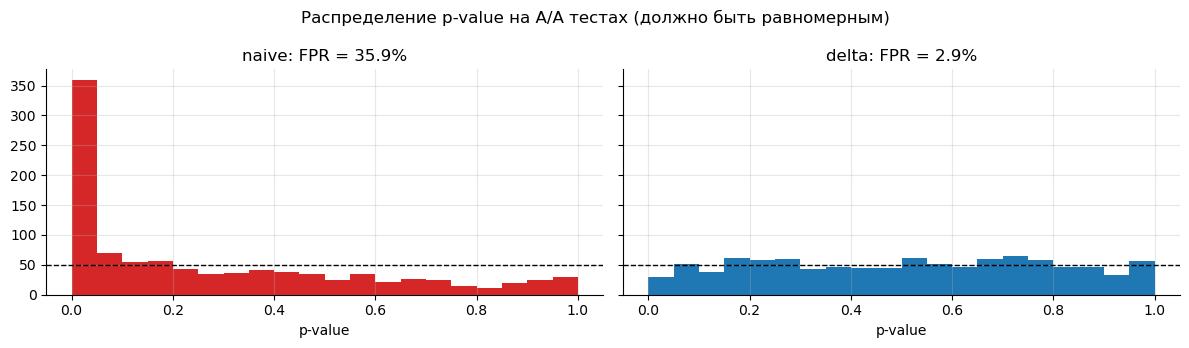

In [4]:
def naive_prop_test(num_c, den_c, num_t, den_t):
    p1, p2 = num_c.sum() / den_c.sum(), num_t.sum() / den_t.sum()
    p = (num_c.sum() + num_t.sum()) / (den_c.sum() + den_t.sum())
    se = np.sqrt(p * (1 - p) * (1 / den_c.sum() + 1 / den_t.sum()))
    return 2 * stats.norm.sf(abs(p2 - p1) / se)

rng = np.random.default_rng(42)
num = pre_users["pre_contacts"].values
den = pre_users["pre_listing_views"].values
res = {"naive": [], "delta": []}
for _ in range(1000):
    m = rng.random(len(num)) < 0.5
    res["naive"].append(naive_prop_test(num[m], den[m], num[~m], den[~m]))
    res["delta"].append(abtest.delta_ratio_test(num[m], den[m], num[~m], den[~m]).p_value)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, (k, v) in zip(ax, res.items()):
    v = np.array(v)
    a.hist(v, bins=20, range=(0, 1), color="C3" if k == "naive" else "C0")
    a.axhline(len(v) / 20, color="k", ls="--", lw=1)
    a.set_title(f"{k}: FPR = {(v < 0.05).mean():.1%}")
    a.set_xlabel("p-value")
plt.suptitle("Распределение p-value на А/А тестах (должно быть равномерным)")
plt.tight_layout()
plt.savefig(f"{FIG}/02_aa_pvalues.png", dpi=120)

Наивный тест дает заметно больше ложных прокрасов, чем заявленные 5%. Дальше для CR использую дельта-метод (и линеаризацию, когда нужен CUPED).

### 1.4 Какой эффект мы вообще можем заметить

Оценка MDE на данных предпериода для нашего размера групп. Для ratio-метрики считаю через дисперсию дельта-метода.

In [5]:
n_group = len(df) // 2
cr_pre = num.sum() / den.sum()
sd_equiv = np.sqrt(abtest.ratio_var(num, den) * len(num))  # "поюзерное" стандартное отклонение CR
mde_abs = abtest.mde(sd_equiv, n_group)

# с CUPED: дисперсия падает в (1 - rho^2) раз, rho — корреляция метрики с ее значением на предпериоде
# корреляцию оцениваем до теста: "псевдо-тест" 14.07-03.08, история — 6 недель перед ним
hist = per_user(pd.Timestamp("2025-06-02"), pd.Timestamp("2025-07-13"))
pseudo = per_user(pd.Timestamp("2025-07-14"), pd.Timestamp("2025-08-03"))
both = pseudo.join(hist, rsuffix="_prev", how="left").fillna(0)
lin = abtest.linearize(both["contacts"], both["listing_views"], cr_pre)
lin_prev = abtest.linearize(both["contacts_prev"], both["listing_views_prev"], cr_pre)
rho = np.corrcoef(lin, lin_prev)[0, 1]
share_with_history = (both["listing_views_prev"] > 0).mean()

print(f"CR на предпериоде: {cr_pre:.4f}")
print(f"MDE (alpha=0.05, power=0.8, {n_group} юзеров в группе): {mde_abs:.4f} абс. = {mde_abs / cr_pre:.1%} отн.")
print(f"корреляция с предпериодом: {rho:.2f}, доля юзеров с историей: {share_with_history:.0%}")
print(f"MDE с CUPED (грубо): {mde_abs * np.sqrt(1 - rho**2) / cr_pre:.1%} отн.")

CR на предпериоде: 0.0600
MDE (alpha=0.05, power=0.8, 24907 юзеров в группе): 0.0019 абс. = 3.1% отн.
корреляция с предпериодом: 0.39, доля юзеров с историей: 51%
MDE с CUPED (грубо): 2.8% отн.


Ожидаемый продуктом эффект — несколько процентов к CR, т.е. на границе чувствительности теста без снижения дисперсии. Поэтому сразу закладываю CUPED с ковариатой из предпериода.

## 2. Результаты

In [6]:
rows = {}
rows["CR (дельта-метод)"] = abtest.delta_ratio_test(ctrl["contacts"], ctrl["listing_views"],
                                                     test["contacts"], test["listing_views"])
for m, name in [("contacts", "контакты / юзер"), ("listing_views", "просмотры / юзер"), ("sessions", "сессии / юзер")]:
    rows[name] = abtest.ttest(ctrl[m], test[m])

# CUPED для CR: линеаризуем и берем линеаризованную метрику предпериода как ковариату
cr_c = ctrl["contacts"].sum() / ctrl["listing_views"].sum()
df["lin"] = abtest.linearize(df["contacts"], df["listing_views"], cr_c)
df["lin_pre"] = abtest.linearize(df["pre_contacts"], df["pre_listing_views"], cr_c)
df["lin_cuped"], theta = abtest.cuped(df["lin"], df["lin_pre"])

lin_plain = abtest.ttest(df.loc[df.variant == "control", "lin"], df.loc[df.variant == "test", "lin"])
lin_cuped = abtest.ttest(df.loc[df.variant == "control", "lin_cuped"], df.loc[df.variant == "test", "lin_cuped"])

# переводим разницу линеаризованной метрики обратно в шкалу CR
scale = ctrl["listing_views"].mean()
for name, r in [("CR (линеаризация)", lin_plain), ("CR (линеаризация + CUPED)", lin_cuped)]:
    rows[name] = abtest.TestResult(cr_c, cr_c + r.diff / scale, r.diff / scale, r.diff / scale / cr_c,
                                   r.ci_low / scale, r.ci_high / scale, r.p_value)

res_tbl = pd.DataFrame({k: vars(v) for k, v in rows.items()}).T
res_tbl["ci_width"] = res_tbl["ci_high"] - res_tbl["ci_low"]
print(f"theta = {theta:.3f}; снижение дисперсии CUPED: {1 - df['lin_cuped'].var() / df['lin'].var():.1%}")
res_tbl.style.format({"control": "{:.4f}", "test": "{:.4f}", "diff": "{:+.4f}", "rel_diff": "{:+.2%}",
                      "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "p_value": "{:.4f}", "ci_width": "{:.4f}"})

theta = 0.326; снижение дисперсии CUPED: 18.4%


,control,test,diff,rel_diff,ci_low,ci_high,p_value,ci_width
CR (дельта-метод),0.0642,0.0664,+0.0022,+3.47%,+0.0007,+0.0038,0.0042,0.0031
контакты / юзер,1.5041,1.5656,+0.0615,+4.09%,+0.0167,+0.1062,0.0071,0.0895
просмотры / юзер,23.4325,23.5714,+0.1388,+0.59%,-0.3035,+0.5812,0.5384,0.8847
сессии / юзер,6.5088,6.5347,+0.0259,+0.40%,-0.0886,+0.1404,0.6575,0.2289
CR (линеаризация),0.0642,0.0664,+0.0022,+3.49%,+0.0007,+0.0038,0.0041,0.0031
CR (линеаризация + CUPED),0.0642,0.0660,+0.0018,+2.84%,+0.0004,+0.0032,0.0098,0.0028


бутстрап: diff = +0.0022, 95% CI [+0.0007; +0.0037], p ~ 0.0090


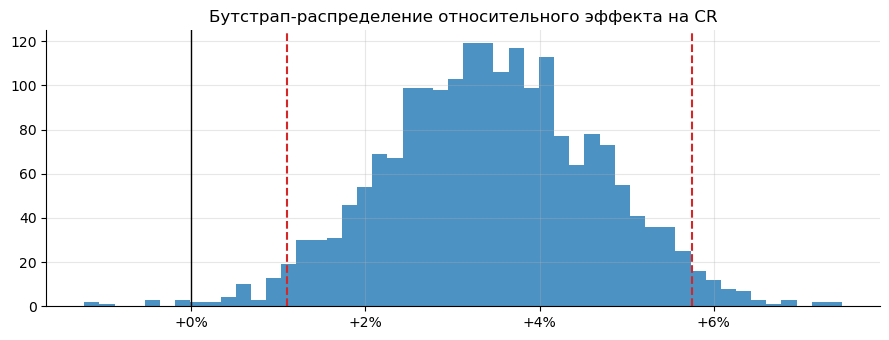

In [7]:
# проверка бутстрапом
diffs, (lo, hi), p_boot = abtest.bootstrap_ratio(ctrl["contacts"].values, ctrl["listing_views"].values,
                                                 test["contacts"].values, test["listing_views"].values,
                                                 n_boot=2000, seed=1)
print(f"бутстрап: diff = {diffs.mean():+.4f}, 95% CI [{lo:+.4f}; {hi:+.4f}], p ~ {p_boot:.4f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(diffs / cr_c, bins=50, color="C0", alpha=0.8)
ax.axvline(0, color="k", lw=1)
ax.axvline(lo / cr_c, color="C3", ls="--"); ax.axvline(hi / cr_c, color="C3", ls="--")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_title("Бутстрап-распределение относительного эффекта на CR")
plt.tight_layout()
plt.savefig(f"{FIG}/02_bootstrap.png", dpi=120)

### Как менялся p-value по дням

Решение принимаем только в конце, по зафиксированной заранее длительности. Но полезно посмотреть, что было бы, если бы мы подглядывали каждый день и остановили тест при первом p < 0.05.

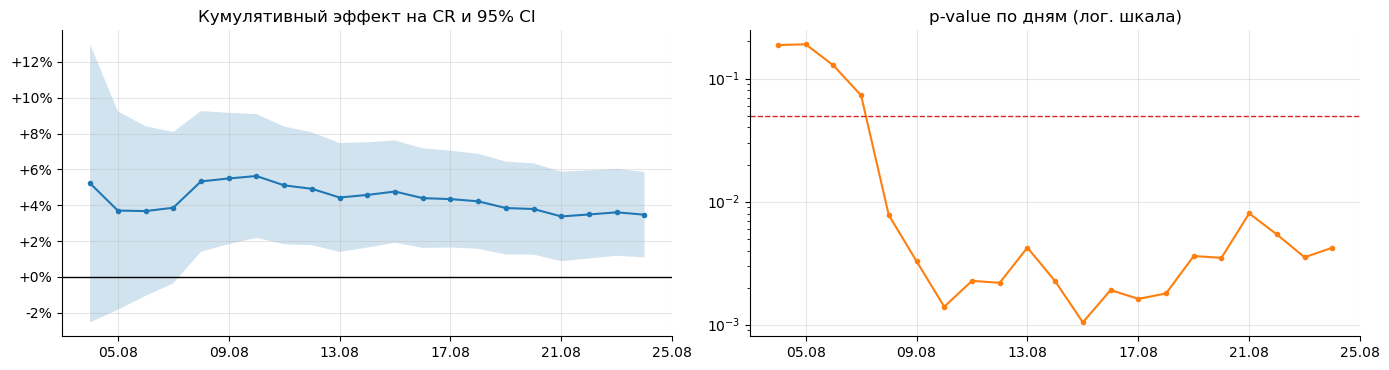

In [8]:
days = pd.date_range(EXP_START, EXP_END)
trace = []
exp_ud = ud[(ud["dt"] >= EXP_START) & (ud["dt"] <= EXP_END)].merge(exp[["user_id", "variant"]], on="user_id")
for d in days:
    cum = exp_ud[exp_ud["dt"] <= d].groupby(["user_id", "variant"])[["contacts", "listing_views"]].sum().reset_index()
    c, t = cum[cum.variant == "control"], cum[cum.variant == "test"]
    r = abtest.delta_ratio_test(c["contacts"], c["listing_views"], t["contacts"], t["listing_views"])
    trace.append((d, r.rel_diff, r.ci_low / r.control, r.ci_high / r.control, r.p_value))
trace = pd.DataFrame(trace, columns=["dt", "rel", "lo", "hi", "p"]).set_index("dt")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(trace.index, trace["rel"], marker="o", ms=3)
ax[0].fill_between(trace.index, trace["lo"], trace["hi"], alpha=0.2)
ax[0].axhline(0, color="k", lw=1)
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax[0].set_title("Кумулятивный эффект на CR и 95% CI")
ax[1].plot(trace.index, trace["p"], marker="o", ms=3, color="C1")
ax[1].axhline(0.05, color="C3", ls="--", lw=1)
ax[1].set_yscale("log")
ax[1].set_title("p-value по дням (лог. шкала)")
for a in ax:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.tight_layout()
plt.savefig(f"{FIG}/02_cumulative.png", dpi=120)

## 3. Разрезы

Смотрю эффект по платформам и ролям. Разрезов много, поэтому применяю поправку Холма — иначе какой-нибудь сегмент обязательно "прокрасится" случайно.

In [9]:
seg_rows = []
for col in ["platform", "role"]:
    for val, g in df.groupby(col):
        c, t = g[g.variant == "control"], g[g.variant == "test"]
        r = abtest.delta_ratio_test(c["contacts"], c["listing_views"], t["contacts"], t["listing_views"])
        seg_rows.append({"срез": col, "сегмент": val, "n": len(g), "cr_control": r.control,
                         "rel_diff": r.rel_diff, "ci_low_rel": r.ci_low / r.control,
                         "ci_high_rel": r.ci_high / r.control, "p_value": r.p_value})
seg = pd.DataFrame(seg_rows)
seg["significant_holm"], seg["p_holm"] = abtest.holm(seg["p_value"])
seg.style.format({"cr_control": "{:.4f}", "rel_diff": "{:+.2%}", "ci_low_rel": "{:+.2%}",
                  "ci_high_rel": "{:+.2%}", "p_value": "{:.4f}", "p_holm": "{:.4f}"})

,срез,сегмент,n,cr_control,rel_diff,ci_low_rel,ci_high_rel,p_value,significant_holm,p_holm
0,platform,android,25946,0.0642,+3.07%,-0.18%,+6.33%,0.0642,False,0.3211
1,platform,ios,11412,0.0690,+7.33%,+2.50%,+12.16%,0.0029,True,0.0175
2,platform,web,12457,0.0582,-0.95%,-5.77%,+3.87%,0.6990,False,1.0000
3,role,agent,6044,0.0380,+2.40%,-3.45%,+8.25%,0.4214,False,1.0000
4,role,buyer,15987,0.0635,-0.29%,-4.39%,+3.81%,0.8886,False,1.0000
5,role,renter,18683,0.0829,+7.36%,+3.72%,+11.01%,0.0001,True,0.0005
6,role,seller,9101,0.0640,+1.79%,-3.67%,+7.26%,0.5204,False,1.0000


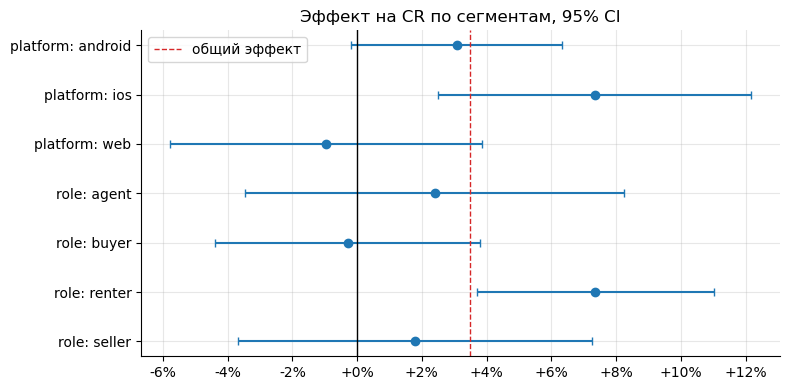

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
lab = seg["срез"] + ": " + seg["сегмент"]
y = np.arange(len(seg))[::-1]
ax.errorbar(seg["rel_diff"], y, xerr=[seg["rel_diff"] - seg["ci_low_rel"], seg["ci_high_rel"] - seg["rel_diff"]],
            fmt="o", capsize=3)
ax.axvline(0, color="k", lw=1)
ax.axvline(rows["CR (дельта-метод)"].rel_diff, color="C3", ls="--", lw=1, label="общий эффект")
ax.set_yticks(y); ax.set_yticklabels(lab)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.02))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.legend()
ax.set_title("Эффект на CR по сегментам, 95% CI")
plt.tight_layout()
plt.savefig(f"{FIG}/02_segments.png", dpi=120)

## 4. Вывод

**Проверки:** SRM нет (p = 0.35, по платформам тоже чисто), на предпериоде группы не отличаются. Наивный z-тест по просмотрам на А/А дал 25% ложных прокрасов вместо 5% — в отчете по тесту его использовать нельзя.

**Целевая метрика.** CR просмотр → контакт вырос на **+2.8%** (CUPED, 95% CI ≈ [+0.7%; +5.0%], p ≈ 0.01). Без CUPED оценка +3.5% — часть разницы объясняется тем, что тестовая группа и до теста конвертировалась чуть лучше (+1.8% на предпериоде, незначимо). CUPED это учитывает, поэтому в итог беру его. Бутстрап согласуется с дельта-методом. Эффект появился с первых дней и стабилен по ходу теста, эффекта новизны не видно, но 3 недель мало, чтобы утверждать это наверняка.

**Guardrails.** Просмотры и сессии на пользователя не изменились (p > 0.5) — галерея не "съела" глубину просмотра. Контакты на пользователя +4.1% (p < 0.01).

**Разрезы.** Значимо после поправки Холма — iOS (+7%) и арендаторы (+7%). На вебе эффект около нуля, CI [-6%; +4%]. Из разрезов не делаю вывод "для покупателей не работает": доверительные интервалы сегментов широкие и пересекаются с общим эффектом, тест не планировался под сегменты.

**Решение:** раскатываем новую карточку на мобильные приложения. По вебу отдельно разобраться с реализацией (на вебе кнопки контакта и так видны сразу на десктопе — возможно, улучшать там нечего) и, если будет доработка, перезапустить тест только на вебе.

**В деньгах (грубо):** +2.8% к CR при ~92k контактов в мобильных приложениях за август — это ~2.5k дополнительных контактов в месяц (на масштабе выборки; на реальной аудитории пропорционально больше). Для платформы, где монетизация в основном на продавцах и агентах, больше контактов = выше ценность размещения и продвижения.

**Что бы я сделал иначе в следующий раз:** заранее зафиксировал бы в дизайне разрез по платформам (web vs app) как отдельную гипотезу — тогда не пришлось бы оговаривать сегменты как post-hoc.